# Pocket Cube · State-space search

**Problem 2** · Shared cube setup, Q1–Q6, V1–V5, verification, and plots.

**Run All** from a fresh kernel. The benchmark at depths 10 and 11 takes longer. The saved outputs show a full run.

**Submission** · Handwritten Q1–Q6 and algorithm diagrams, the group slide deck, and the combined code.

## Cube representation and moves

## 0.1 How the cube is stored

A 2×2×2 cube has 8 corner pieces. Turning the *whole* cube changes nothing, so we keep one corner (the bottom-back-left) fixed and track the other **7 corners**.

The places a corner can sit are called **slots**:

```
 Top layer (seen from above, FRONT at the bottom)        Bottom layer (directly below)

        back                                                   back
   3 ─────────── 2                                        7 ─────────── 6
   │ UBL     UBR │                                        │ DBL     DBR │
   │             │                                        │  (fixed)    │
   │ UFL     UFR │                                        │ DFL     DFR │
   0 ─────────── 1                                        4 ─────────── 5
        front                                                  front
```

We store a state as two tuples (fixed sequences) of 7 numbers:

* **perm** — which corner piece sits in each slot. `perm[1] = 5` means *slot 1 currently holds piece number 5*.
* **orient** — how twisted that piece is: `0`, `1` or `2` (a corner can be twisted three ways).

The solved cube is `perm = (0,1,2,3,4,5,6)` and `orient = (0,0,0,0,0,0,0)`.

Because slot 7 never moves, we only need to turn three faces: **U** (up), **R** (right) and **F** (front). Each can turn clockwise or counter-clockwise, so there are **6 moves**:

`0 = U`, `1 = U'`, `2 = R`, `3 = R'`, `4 = F`, `5 = F'`   (the apostrophe means counter-clockwise)

In [1]:
from collections import deque
# Solved Pocket Rubik's Cube
SOLVED_STATE = (
    (0, 1, 2, 3, 4, 5, 6),
    (0, 0, 0, 0, 0, 0, 0)
)

# Move definitions: (target positions, source positions, orientation changes)
MOVES = {
    "R": (
        (1, 2, 6, 5),
        (5, 1, 2, 6),
        (1, 2, 1, 2)
    ),

    "R'": (
        (1, 2, 6, 5),
        (2, 6, 5, 1),
        (1, 2, 1, 2)
    ),

    "U": (
        (0, 3, 2, 1),
        (1, 0, 3, 2),
        (0, 0, 0, 0)
    ),

    "U'": (
        (0, 3, 2, 1),
        (3, 2, 1, 0),
        (0, 0, 0, 0)
    ),

    "F": (
        (0, 1, 5, 4),
        (4, 0, 1, 5),
        (1, 2, 1, 2)
    ),

    "F'": (
        (0, 1, 5, 4),
        (1, 5, 4, 0),
        (1, 2, 1, 2)
    )
}


def apply_move(state, move):

    # Current permutation and orientation
    perm, orient = state

    # Check whether the move exists
    if move not in MOVES:
        raise ValueError("Invalid move!")

    # Move instructions
    targets, sources, twists = MOVES[move]

    # Copies of the current state
    new_perm = list(perm)
    new_orient = list(orient)

    # Apply the movement to four corners
    for target, source, twist in zip(targets, sources, twists):

        # Move the corner cubie
        new_perm[target] = perm[source]

        # Update corner orientation
        new_orient[target] = (orient[source] + twist) % 3

    # Return a new immutable state
    return (
        tuple(new_perm),
        tuple(new_orient)
    )


def apply_sequence(state, moves):

    # Apply several moves one by one
    for move in moves:
        state = apply_move(state, move)

    return state

### Q1 · Tuple trace

`s₀ --R--> s₁ --U--> s₂ --R′--> s₃`

### Q2 · Twist sum

- Each move preserves the sum of twists modulo 3
- Legal moves add a total of 0 or 6 before reducing twists modulo 3
- A single corner twisted by hand changes the remainder. Legal turns preserve that remainder, so the cube cannot return to solved.

In [2]:
# Test Question 1
s0 = SOLVED_STATE
s1 = apply_move(s0, "R")
s2 = apply_move(s1, "U")
s3 = apply_move(s2, "R'")

print("QUESTION #1")
print(f"Initial state: {s0}")
print(f"After R: {s1}")
print(f"After U: {s2}")
print(f"After R': {s3}")

# Test Question 2
print("\nQUESTION #2")

for name, state in [
    ("s1", s1),
    ("s2", s2),
    ("s3", s3)
]:
    orientation_sum = sum(state[1])
    assert orientation_sum % 3 == 0

    print(
        name,
        "Orientation sum:",
        orientation_sum,
        "Valid:",
        orientation_sum % 3 == 0
    )

# Test R followed by R'
test_state = apply_sequence(
    SOLVED_STATE,
    ["R", "R'"]
)

assert test_state == SOLVED_STATE

print(f"R --> R': {test_state}")
print("\nAll tests passed!")

# Check the inverses on a mixed cube as well.
for move, undo in [("R", "R'"), ("U", "U'"), ("F", "F'")]:
    assert apply_sequence(s3, [move, undo]) == s3
    assert apply_sequence(s3, [undo, move]) == s3
    assert apply_sequence(s3, [move] * 4) == s3

print("All inverse and four-turn checks passed.")

QUESTION #1
Initial state: ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))
After R: ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))
After U: ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1))
After R': ((5, 3, 2, 0, 4, 1, 6), (1, 1, 0, 0, 0, 1, 0))

QUESTION #2
s1 Orientation sum: 6 Valid: True
s2 Orientation sum: 6 Valid: True
s3 Orientation sum: 3 Valid: True
R --> R': ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))

All tests passed!
All inverse and four-turn checks passed.


## V1 · Unpruned depth-first search

Convert the starting and goal tuples to 24-sticker color lists. Use a stack of states and their move paths. Stop at the depth limit.

In [3]:
# Each piece's three colors in twist order, starting with its U or D color.
CORNER_COLORS = ("ULF", "UFR", "URB", "UBL", "DFL", "DRF", "DBR", "DLB")


def state_to_stickers(state):
    """Turn (perm, orient) into a list of 24 sticker colors."""
    perm, orient = state
    stickers = []
    for slot in range(7):
        colors = CORNER_COLORS[perm[slot]]
        for k in range(3):
            stickers.append(colors[(k - orient[slot]) % 3])
    stickers.extend(CORNER_COLORS[7])  # The fixed corner.
    return stickers


# Sticker positions before each turn.
STICKER_SOURCE = {}
for move, (targets, sources, twists) in MOVES.items():
    source = list(range(24))
    for dest, src, twist in zip(targets, sources, twists):
        for k in range(3):
            source[3 * dest + k] = 3 * src + (k - twist) % 3
    STICKER_SOURCE[move] = source


def apply_move_to_stickers(stickers, move):
    """Do one move on a 24-sticker list (returns a new list)."""
    return [stickers[i] for i in STICKER_SOURCE[move]]

In [4]:
def v1_dfs_unpruned(start, goal, max_depth):

    # Stack stores (24 sticker colors, moves used)
    goal_stickers = state_to_stickers(goal)
    stack = [(state_to_stickers(start), [])]

    # Count explored states
    explored = 0

    # Get all available moves
    moves = list(MOVES.keys())

    while stack:

        # Take the most recently added state
        stickers, path = stack.pop()

        explored += 1

        # Check whether the goal is found
        if stickers == goal_stickers:
            return path, explored

        # Do not search beyond maximum depth
        if len(path) >= max_depth:
            continue

        # Explore possible next moves
        for move in reversed(moves):

            new_stickers = apply_move_to_stickers(stickers, move)
            new_path = path + [move]

            stack.append((new_stickers, new_path))

    # No solution found within maximum depth
    return None, explored

## V2 · Unidirectional BFS

Use a FIFO queue and a parent dictionary. Return the shortest path when the goal is removed from the queue.

In [5]:
def v2_bfs_unidirectional(start, goal):

    # Queue stores states waiting to be explored
    queue = deque([start])

    # Remember where each state came from
    # This helps reconstruct the solution
    parent = {
        start: (None, None)
    }

    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1}

    # Get all available moves
    moves = list(MOVES.keys())

    while queue:

        # Remove the oldest state from the queue
        state = queue.popleft()


        # Check whether the goal is found
        if state == goal:

            # Reconstruct the solution path
            path = []
            current = state

            while parent[current][0] is not None:

                previous_state, move = parent[current]

                path.append(move)

                current = previous_state

            # Reverse the path into the correct order
            path.reverse()

            stats["max_stored"] = len(parent)
            return path, stats

        # Explore possible next moves
        stats["expanded"] += 1
        for move in moves:
            stats["moves_tried"] += 1

            new_state = apply_move(state, move)

            # Only visit states that have not been seen
            if new_state not in parent:

                parent[new_state] = (state, move)

                queue.append(new_state)

    # No solution found
    stats["max_stored"] = len(parent)
    return None, stats

### V1 and V2 · One-turn test

In [6]:
# Create a scrambled cube using one move
test_start = apply_move(SOLVED_STATE, "R")

# The goal is the solved cube
test_goal = SOLVED_STATE

print("Starting scrambled cube:", test_start)
print("Goal cube:", test_goal)

# Run DFS with a depth limit
dfs_path, dfs_explored = v1_dfs_unpruned(
    test_start,
    test_goal,
    max_depth=5
)

# Run BFS
bfs_path, bfs_stats = v2_bfs_unidirectional(
    test_start,
    test_goal
)

# Display DFS results
print("\n========== DFS RESULTS ==========")

print("Solution:", dfs_path)

print(
    "Number of moves:",
    len(dfs_path) if dfs_path is not None else None
)

print("States explored:", dfs_explored)


# Display BFS results
print("\n========== BFS RESULTS ==========")

print("Solution:", bfs_path)

print(
    "Number of moves:",
    len(bfs_path) if bfs_path is not None else None
)

print("States expanded:", bfs_stats["expanded"])
print("Moves tried:", bfs_stats["moves_tried"])
print("Peak stored:", bfs_stats["max_stored"])
# Verify DFS solution

if dfs_path is not None:

    dfs_result = apply_sequence(
        test_start,
        dfs_path
    )

    print(
        "DFS reaches solved cube:",
        dfs_result == test_goal
    )

    assert dfs_result == test_goal

else:
    print("DFS did not find a solution.")


# Verify BFS solution

if bfs_path is not None:

    bfs_result = apply_sequence(
        test_start,
        bfs_path
    )

    print(
        "BFS reaches solved cube:",
        bfs_result == test_goal
    )

    assert bfs_result == test_goal

else:
    print("BFS did not find a solution.")


# Compare solution lengths
if dfs_path is not None and bfs_path is not None:

    print("\n========== COMPARISON ==========")

    print("DFS solution length:", len(dfs_path))
    print("BFS solution length:", len(bfs_path))

    print(
        "BFS solution is no longer than DFS:",
        len(bfs_path) <= len(dfs_path)
    )

print("\nAll available solution paths verified!")

Starting scrambled cube: ((0, 5, 1, 3, 4, 6, 2), (0, 1, 2, 0, 0, 2, 1))
Goal cube: ((0, 1, 2, 3, 4, 5, 6), (0, 0, 0, 0, 0, 0, 0))

========== DFS RESULTS ==========
Solution: ['R', 'R', 'R']
Number of moves: 3
States explored: 4

========== BFS RESULTS ==========
Solution: ["R'"]
Number of moves: 1
States expanded: 2
Moves tried: 12
Peak stored: 12
DFS reaches solved cube: True
BFS reaches solved cube: True

========== COMPARISON ==========
DFS solution length: 3
BFS solution length: 1
BFS solution is no longer than DFS: True

All available solution paths verified!


## Q3 · Path counts at depth 12

- V2 · Six choices per turn
- V3 counting rule · Six first, then four on the other faces
- V4 counting rule · Two searches, six turns deep each
- Counts at the final level under these rules

In [7]:
# Q3 model counts
n2 = 6 ** 12
n3 = 6 * 4 ** 11
n4 = 2 * (6 * 4 ** 5)

print("Q3 — Model path counts")
print(f"N2 = {n2:,}")
print(f"N3 = {n3:,}")
print(f"N4 = {n4:,}")
print(f"N2 / N4 = {n2 // n4:,}")

Q3 — Model path counts
N2 = 2,176,782,336
N3 = 25,165,824
N4 = 12,288
N2 / N4 = 177,147


## V3 and V4 · Search helpers

In [8]:
# Search helpers
from collections import deque

# My move order for both searches
MOVE_ORDER = ("U", "U'", "R", "R'", "F", "F'")
INVERSE = {
    "U": "U'", "U'": "U",
    "R": "R'", "R'": "R",
    "F": "F'", "F'": "F",
}


def rebuild_path(parent, state):
    """Rebuild moves from parent links."""
    path = []
    while parent[state] is not None:
        state, move = parent[state]
        path.append(move)
    # Reverse my backtracked moves
    path.reverse()
    return path


def is_redundant(move, last_move, repeats):
    """Check for a redundant move."""
    if last_move is None:
        return False
    if move == INVERSE[last_move]:
        return True
    if move == last_move and repeats == 2:
        return True
    return False

### V3 · Move-pruned BFS

- `R R′` · Skip the undo
- `R R R` · Same as one `R′`
- `R R` · Keep the half-turn
- Queue entry · Cube state, last move, and repeat count

In [9]:
# V3 · Move-pruned BFS
def v3_bfs_move_pruned(start, goal):
    """Return the shortest path and search stats."""
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1}
    if start == goal:
        return [], stats

    parent = {start: None}
    # Queue entry: state, last move, streak
    queue = deque([(start, None, 0)])

    while queue:
        state, last_move, repeats = queue.popleft()
        stats["expanded"] += 1
        for move in MOVE_ORDER:
            if is_redundant(move, last_move, repeats):
                continue
            new_state = apply_move(state, move)
            stats["moves_tried"] += 1
            if new_state not in parent:
                parent[new_state] = (state, move)
                if new_state == goal:
                    stats["max_stored"] = len(parent)
                    return rebuild_path(parent, new_state), stats
                new_repeats = repeats + 1 if move == last_move else 1
                queue.append((new_state, move, new_repeats))
    stats["max_stored"] = len(parent)
    return None, stats

### Q4 · Hand trace

```text
Scramble side    s3 --R--> s2
Goal side        s0 --R--> s1 --U--> s2
```

Meet at **s₂**. Reverse and undo the goal-side turns `R U` to get `U′ R′`. Add the forward `R` for **`R U′ R′`**.

In [10]:
# My Q4 hand trace
forward_moves = ["R"]       # s3 -> s2
backward_moves = ["R", "U"]   # solved -> s1 -> s2
assert apply_sequence(s3, forward_moves) == s2
assert apply_sequence(SOLVED_STATE, backward_moves) == s2

# Reverse and undo the goal-side moves
finish_moves = [INVERSE[move] for move in reversed(backward_moves)]
hand_solution = forward_moves + finish_moves
assert apply_sequence(s3, hand_solution) == SOLVED_STATE

print("\nQ4 — Hand trace")
print("Scramble side: s3 --R--> s2")
print("Goal side:     s0 --R--> s1 --U--> s2")
print("Meeting state s2 =", s2)
print("Solution =", " ".join(hand_solution))


Q4 — Hand trace
Scramble side: s3 --R--> s2
Goal side:     s0 --R--> s1 --U--> s2
Meeting state s2 = ((5, 1, 3, 0, 4, 6, 2), (1, 2, 0, 0, 0, 2, 1))
Solution = R U' R'


### V4 · Bidirectional BFS

- One current layer and one parent dictionary per side
- Alternate full layers and join the paths at their first overlap
- The demo code meets at `s₁`. The Q4 trace meets at `s₂`.
- The V2 comparison keeps its original move order and checks the goal when dequeued. V3 checks at discovery. The operation counts include these implementation differences.

In [11]:
# V4 · Bidirectional BFS
def expand_one_level(frontier, parent, other_parent, stats):
    """Expand one layer and collect meetings."""
    next_ring = []
    meetings = []
    for state in frontier:
        stats["expanded"] += 1
        for move in MOVE_ORDER:
            new_state = apply_move(state, move)
            stats["moves_tried"] += 1
            if new_state in parent:
                continue
            parent[new_state] = (state, move)
            next_ring.append(new_state)
            if new_state in other_parent:
                meetings.append(new_state)
    return next_ring, meetings


def v4_bfs_bidirectional(start, goal):
    """Return the shortest path and search stats."""
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 1, "meeting_state": None}
    if start == goal:
        stats["meeting_state"] = start
        return [], stats

    parent_f, ring_f = {start: None}, [start]
    parent_b, ring_b = {goal: None}, [goal]
    forward_turn = True
    stats["max_stored"] = 2

    while ring_f and ring_b:
        if forward_turn:
            ring_f, meetings = expand_one_level(ring_f, parent_f, parent_b, stats)
        else:
            ring_b, meetings = expand_one_level(ring_b, parent_b, parent_f, stats)
        stats["max_stored"] = len(parent_f) + len(parent_b)

        if meetings:
            meet = min(meetings)
            stats["meeting_state"] = meet
            start_to_meet = rebuild_path(parent_f, meet)
            goal_to_meet = rebuild_path(parent_b, meet)
            # Reverse and undo my goal-side moves
            meet_to_goal = [INVERSE[move] for move in reversed(goal_to_meet)]
            return start_to_meet + meet_to_goal, stats

        forward_turn = not forward_turn
    return None, stats

In [12]:
print("Scramble: R U R'")
for solve in (v2_bfs_unidirectional, v3_bfs_move_pruned, v4_bfs_bidirectional):
    path, stats = solve(s3, SOLVED_STATE)
    assert path == ["R", "U'", "R'"]
    assert apply_sequence(s3, path) == SOLVED_STATE
    print(
        f"{solve.__name__}: {' '.join(path)} | "
        f"expanded {stats['expanded']} | moves tried {stats['moves_tried']} | "
        f"peak stored {stats['max_stored']}"
    )

_, v4_stats = v4_bfs_bidirectional(s3, SOLVED_STATE)
assert v4_stats["meeting_state"] == s1
print("V4 code meets at s1.")

Scramble: R U R'
v2_bfs_unidirectional: R U' R' | expanded 44 | moves tried 264 | peak stored 199
v3_bfs_move_pruned: R U' R' | expanded 18 | moves tried 88 | peak stored 81
v4_bfs_bidirectional: R U' R' | expanded 8 | moves tried 48 | peak stored 41
V4 code meets at s1.


## Q5 and V5 · Corner heuristic and IDA*

Count each slot with the wrong corner or twist. One turn affects at most four corners, so round the count divided by four up to the next whole number. This is a lower bound. For `s₁`, the four affected slots are 1, 2, 5, and 6. The heuristic is **1**, matching the single turn `R′`.

V5 checks `moves used + estimated moves remaining` against its current limit. Increase the limit to the smallest rejected value when a round fails.

In [13]:
import math

def heuristic(state, goal):
    # number of corners in the wrong slot or twisted, divided by 4 (rounded up)
    wrong = sum(1 for i in range(7) if state[0][i] != goal[0][i] or state[1][i] != goal[1][i])
    return math.ceil(wrong / 4)

def inverse(move):
    # R <-> R'
    if move.endswith("'"):
        return move[0]
    return move + "'"

In [14]:
def v5_ida_star(start, goal):
    path = []
    stats = {"expanded": 0, "moves_tried": 0, "max_stored": 0}

    def search(state, g, T):
        # Include the current state on the recursion stack.
        stats["max_stored"] = max(stats["max_stored"], g + 1)
        f = g + heuristic(state, goal)
        if f > T:
            return f                      # too long: cut this branch
        if state == goal:
            return "FOUND"
        stats["expanded"] += 1
        smallest = math.inf
        for move in MOVES:
            if path and move == inverse(path[-1]):
                continue                  # don't undo the last move
            stats["moves_tried"] += 1
            path.append(move)
            result = search(apply_move(state, move), g + 1, T)
            if result == "FOUND":
                return "FOUND"
            path.pop()
            smallest = min(smallest, result)
        return smallest

    T = heuristic(start, goal)
    while T <= 14:                        # 14 = longest possible solution
        result = search(start, 0, T)
        if result == "FOUND":
            return path, stats
        T = result                        # try again with a bigger limit
    return None, stats

In [15]:
path, stats = v5_ida_star(s3, SOLVED_STATE)
assert path == ["R", "U'", "R'"]
assert apply_sequence(s3, path) == SOLVED_STATE
print("h(s1) =", heuristic(s1, SOLVED_STATE))
print("V5 on s3 =", " ".join(path))
print(stats)

h(s1) = 1
V5 on s3 = R U' R'
{'expanded': 7, 'moves_tried': 28, 'max_stored': 4}


## Q6 · Complexity comparison

`d` is the shortest solution length. `D` is the DFS depth cap. Time and space below are upper bounds using the move tree, with at most six moves per state.

| Version | Main data structures | Time | Peak memory | Shortest? |
|---|---|---|---|---|
| V1 DFS | 24-sticker states and copied paths on a stack | O(D × 6^D) | O(D²) | No |
| V2 BFS | FIFO queue and parent dictionary | O(6^d) | O(6^d) | Yes |
| V3 pruned BFS | Queue with move history and parent dictionary | O(5^d) | O(5^d) | Yes |
| V4 bidirectional BFS | Two current layers and two parent dictionaries | O(6^ceil(d/2)) | O(6^ceil(d/2)) | Yes |
| V5 IDA* | Current path and recursion stack | O(5^d) | O(d) | Yes |

V1 copies the move list for each branch. The stack can hold O(D) pending branches for fixed branching factor, each with O(D) moves. V3 and V5 try at most five moves after the first turn. V2 can discover some states at depth d + 1 before the goal is removed from the queue. This adds a constant factor for a fixed branching factor.

## Verification suite

20 trials at each **true** shortest depth from 1 through 6. V2–V5 must agree and solve the cube when their moves are applied. V1 checks solution validity within its depth cap. Trials can repeat at shallow depths.

In [16]:
import random

def random_scramble(depth, rng):
    moves = []
    while len(moves) < depth:
        move = rng.choice(MOVE_ORDER)
        if not moves or move != INVERSE[moves[-1]]:
            moves.append(move)
    return moves


def scramble_at_depth(depth, rng):
    while True:
        moves = random_scramble(depth, rng)
        start = apply_sequence(SOLVED_STATE, moves)
        path, _ = v4_bfs_bidirectional(start, SOLVED_STATE)
        if len(path) == depth:
            return start


optimal_solvers = {
    "V2 BFS": v2_bfs_unidirectional,
    "V3 pruned BFS": v3_bfs_move_pruned,
    "V4 bidirectional BFS": v4_bfs_bidirectional,
    "V5 IDA*": v5_ida_star,
}

rng = random.Random(42)
verification_total = 0
for depth in range(1, 7):
    for _ in range(20):
        start = scramble_at_depth(depth, rng)
        for name, solve in optimal_solvers.items():
            path, _ = solve(start, SOLVED_STATE)
            assert path is not None, (name, depth)
            assert len(path) == depth, (name, depth, path)
            assert apply_sequence(start, path) == SOLVED_STATE, (name, depth)
        path, _ = v1_dfs_unpruned(start, SOLVED_STATE, max_depth=depth)
        assert path is not None and apply_sequence(start, path) == SOLVED_STATE
        verification_total += 1
    print(f"Depth {depth}: 20 trials passed.")
print(f"{verification_total} total trials passed.")

Depth 1: 20 trials passed.
Depth 2: 20 trials passed.
Depth 3: 20 trials passed.
Depth 4: 20 trials passed.
Depth 5: 20 trials passed.
Depth 6: 20 trials passed.
120 total trials passed.


## Benchmark

V2–V5 on the same two distinct random cubes at each true depth **2, 4, 6, 8, 10, and 11**. Timing covers the solver call. Expanded states and time are averaged across the two cubes. The memory plot uses the larger peak across the two runs.

**Expanded** · States whose moves are tried. **Peak stored** · Parent dictionary entries for V2–V4, including both sides for V4. Active recursion states for V5.

In [17]:
import time

DEPTHS = [2, 4, 6, 8, 10, 11]
SCRAMBLES_PER_DEPTH = 2
rng = random.Random(2026)
results = {name: {} for name in optimal_solvers}

for depth in DEPTHS:
    # Same distinct starting cubes for every solver at this depth.
    starts = []
    while len(starts) < SCRAMBLES_PER_DEPTH:
        start = scramble_at_depth(depth, rng)
        if start not in starts:
            starts.append(start)

    print(f"Depth {depth}", flush=True)
    for name, solve in optimal_solvers.items():
        expanded, stored, seconds = [], [], []
        for start in starts:
            t0 = time.perf_counter()
            path, stats = solve(start, SOLVED_STATE)
            seconds.append(time.perf_counter() - t0)
            assert path is not None and len(path) == depth
            assert apply_sequence(start, path) == SOLVED_STATE
            expanded.append(stats["expanded"])
            stored.append(stats["max_stored"])

        average_expanded = sum(expanded) / len(starts)
        average_seconds = sum(seconds) / len(starts)
        peak_stored = max(stored)
        results[name][depth] = {
            "expanded": average_expanded,
            "seconds": average_seconds,
            "stored": peak_stored,
        }
        print(
            f"  {name}: {average_expanded:,.1f} expanded | "
            f"{average_seconds:.5f} s | {peak_stored:,} peak stored",
            flush=True,
        )

Depth 2
  V2 BFS: 21.0 expanded | 0.00013 s | 132 peak stored
  V3 pruned BFS: 5.5 expanded | 0.00013 s | 30 peak stored
  V4 bidirectional BFS: 2.0 expanded | 0.00006 s | 14 peak stored
  V5 IDA*: 2.5 expanded | 0.00010 s | 3 peak stored
Depth 4
  V2 BFS: 600.0 expanded | 0.00661 s | 2,619 peak stored
  V3 pruned BFS: 134.5 expanded | 0.00073 s | 604 peak stored
  V4 bidirectional BFS: 14.0 expanded | 0.00008 s | 68 peak stored
  V5 IDA*: 45.0 expanded | 0.00044 s | 5 peak stored
Depth 6
  V2 BFS: 9,722.0 expanded | 0.10201 s | 43,181 peak stored
  V3 pruned BFS: 1,908.5 expanded | 0.01456 s | 10,863 peak stored
  V4 bidirectional BFS: 68.0 expanded | 0.00039 s | 308 peak stored
  V5 IDA*: 963.0 expanded | 0.00946 s | 7 peak stored
Depth 8
  V2 BFS: 87,009.0 expanded | 0.71239 s | 303,673 peak stored
  V3 pruned BFS: 24,058.5 expanded | 0.23028 s | 127,262 peak stored
  V4 bidirectional BFS: 308.0 expanded | 0.00193 s | 1,376 peak stored
  V5 IDA*: 13,430.5 expanded | 0.17701 s | 9 pe

### Plot 1 · Expanded states and time

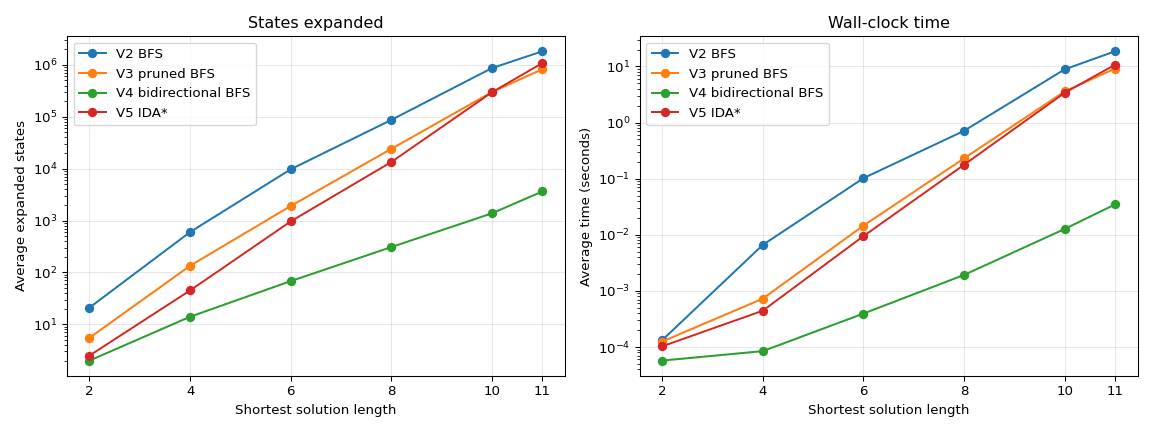

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, rows in results.items():
    axes[0].plot(DEPTHS, [rows[d]["expanded"] for d in DEPTHS], "o-", label=name)
    axes[1].plot(DEPTHS, [rows[d]["seconds"] for d in DEPTHS], "o-", label=name)

axes[0].set_title("States expanded")
axes[0].set_ylabel("Average expanded states")
axes[1].set_title("Wall-clock time")
axes[1].set_ylabel("Average time (seconds)")
for ax in axes:
    ax.set_yscale("log", base=10)
    ax.set_xlabel("Shortest solution length")
    ax.set_xticks(DEPTHS)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

### Plot 2 · Peak states stored

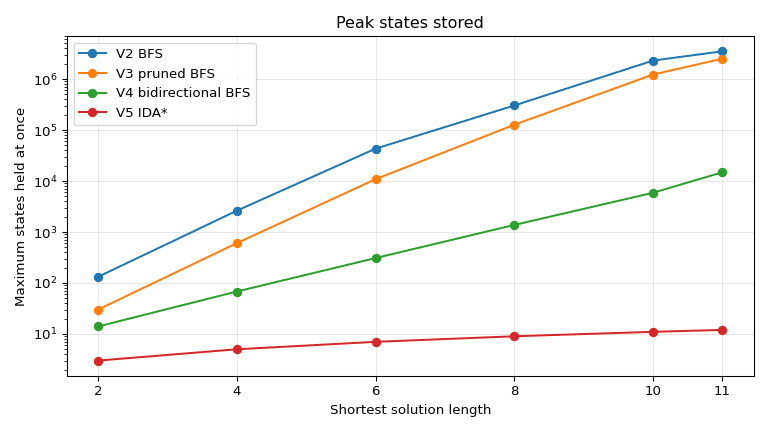

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, rows in results.items():
    ax.plot(DEPTHS, [rows[d]["stored"] for d in DEPTHS], "o-", label=name)

ax.set_title("Peak states stored")
ax.set_xlabel("Shortest solution length")
ax.set_ylabel("Maximum states held at once")
ax.set_yscale("log", base=10)
ax.set_xticks(DEPTHS)
ax.grid(True, which="major", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [20]:
deepest = results["V2 BFS"][11]
print(f"At depth 11, V2 peaked at {deepest['stored']:,} stored states.")
for name in ("V3 pruned BFS", "V4 bidirectional BFS", "V5 IDA*"):
    row = results[name][11]
    print(f"{name} peaked at {row['stored']:,} stored states.")

At depth 11, V2 peaked at 3,512,840 stored states.
V3 pruned BFS peaked at 2,514,060 stored states.
V4 bidirectional BFS peaked at 14,857 stored states.
V5 IDA* peaked at 12 stored states.
